# 05 - The full KITTI study: a learned shadow detector and four depth models

Notebook 03 used one drive, DA-V2-S and a dark-asphalt threshold. Here the same corruptions
run on 5 drives (71 frames) with four depth models (DA-V2-S/L, Depth Pro, MoGe-2-L) and two
shadow detectors: the threshold and a SegFormer mit-b2 trained on ISTD
(`scripts/shadow_study.py`, run on Kaggle; results in `outputs/study/`).

A label-free check needs more than "the score moves". For each corruption the score must be
**highest at the true value** (1 for scale, shape and focal, 0 degrees for the sun). We test that
per frame, with intervals from a bootstrap over drives (frames of one drive are not independent).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "outputs/figures"
STUDY = ROOT / "outputs/study"

d = pd.read_csv(STUDY / "shadow_study.csv")
net = json.loads((STUDY / "shadow_net.json").read_text())
TRUE = {"scale": 1.0, "shape": 1.0, "focal": 1.0, "sun_azimuth": 0.0}
MODELS = ["dav2-s", "dav2-l", "depthpro", "moge2-l"]
LABEL = {"dav2-s": "DA-V2-S", "dav2-l": "DA-V2-L", "depthpro": "Depth Pro", "moge2-l": "MoGe-2-L"}
COLOUR = {"dav2-s": "#E69F00", "dav2-l": "#D55E00", "depthpro": "#0072B2", "moge2-l": "#009E73"}
print(f"{d.drive.nunique()} drives, {d.groupby('drive').frame.nunique().sum()} frames, sun elevation "
      f"{d.elevation.min():.1f}-{d.elevation.max():.1f} deg")
print(f"shadow detector: {net['backbone']} on ISTD, test BER {net['istd_test_ber']:.2f} %")

5 drives, 71 frames, sun elevation 39.7-39.8 deg
shadow detector: nvidia/mit-b2 on ISTD, test BER 1.88 %


In [2]:
def boot_drive(v, n=2000, seed=0):
    """95 % interval of the mean of per-case values v (indexed by drive) when whole drives are resampled."""
    rng = np.random.default_rng(seed)
    per = v.groupby(level="drive").agg(["sum", "count"])
    pick = rng.integers(0, len(per), size=(n, len(per)))
    means = per["sum"].values[pick].sum(1) / per["count"].values[pick].sum(1)
    return np.percentile(means, [2.5, 97.5])

## 1. Score against corruption strength

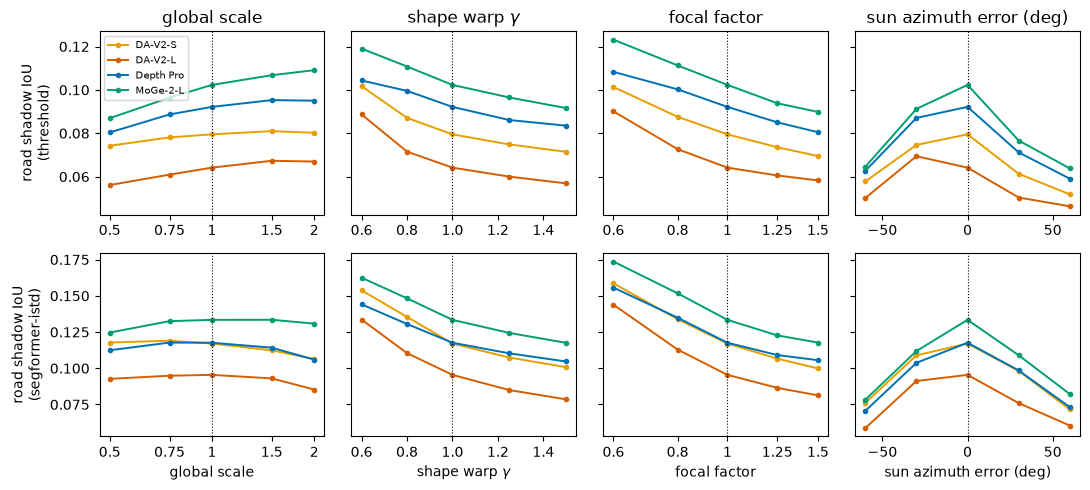

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5), sharey="row")
for i, det in enumerate(["threshold", "segformer-istd"]):
    for j, (c, title) in enumerate([("scale", "global scale"), ("shape", "shape warp $\\gamma$"),
                                    ("focal", "focal factor"), ("sun_azimuth", "sun azimuth error (deg)")]):
        ax = axes[i, j]
        for m in MODELS:
            g = d[(d.detector == det) & (d.corruption == c) & (d.model == m)]
            mean = g.groupby("value").iou.mean()
            ax.plot(mean.index, mean.values, "o-", ms=3, lw=1.4, color=COLOUR[m], label=LABEL[m])
        ax.axvline(TRUE[c], color="k", lw=0.8, ls=":")
        ax.set(xlabel=title if i else None, title=title if not i else None)
        if c in ("scale", "focal"):
            ax.set_xscale("log")
            ticks = sorted(g.value.unique())
            ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
            ax.minorticks_off()
    axes[i, 0].set_ylabel(f"road shadow IoU\n({det})")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.savefig(FIG / "05_kitti_study.png", dpi=90)

## 2. Is the score highest at the truth?
Share of (frame, model) cases whose best-scoring value is the true one, against chance
(1 in 5 values). And the paired IoU gain from the most "compressed" value (0.6 for shape and
focal, 0.5 for scale) over the truth: positive means the wrong depth scores better.

In [4]:
rows = []
for (det, c), g in d.groupby(["detector", "corruption"]):
    # one value per (frame, model) case
    w = g.pivot_table(index=["drive", "frame", "model"], columns="value", values="iou")
    at_truth = (w.idxmax(axis=1) == TRUE[c]).astype(float)
    low = {"scale": 0.5, "shape": 0.6, "focal": 0.6, "sun_azimuth": -60.0}[c]
    gain = w[low] - w[TRUE[c]]
    lo, hi = boot_drive(at_truth)
    glo, ghi = boot_drive(gain)
    rows.append(dict(detector=det, corruption=c, argmax_at_truth=at_truth.mean(), lo=lo, hi=hi,
                     gain_wrong_minus_true=gain.mean(), gain_lo=glo, gain_hi=ghi))
truth = pd.DataFrame(rows)
truth.round(3).to_csv(STUDY / "argmax_at_truth.csv", index=False)
truth.round(3)

,detector,corruption,argmax_at_truth,lo,hi,gain_wrong_minus_true,gain_lo,gain_hi
0,segformer-istd,focal,0.053,0.028,0.077,0.042,-0.002,0.105
1,segformer-istd,scale,0.102,0.060,0.151,-0.004,-0.017,0.010
2,segformer-istd,shape,0.099,0.015,0.197,0.033,-0.004,0.090
3,segformer-istd,sun_azimuth,0.264,0.093,0.455,-0.045,-0.082,-0.000
4,threshold,focal,0.060,0.027,0.106,0.021,-0.004,0.048
5,threshold,scale,0.074,0.040,0.119,-0.010,-0.021,0.001
6,threshold,shape,0.049,0.035,0.067,0.019,-0.005,0.055
7,threshold,sun_azimuth,0.225,0.080,0.396,-0.026,-0.057,0.005


## 3. Does the score rank depth models?
A useful check should rank models like their accuracy. On KITTI DA-V2-L is more accurate than
DA-V2-S (the zoom audit, and the models' own reports).

In [5]:
rank = d[(d.corruption == "scale") & (d.value == 1.0)].groupby(["detector", "model"]).iou.mean().unstack()
rank = rank[MODELS].rename(columns=LABEL)
rank.round(3).to_csv(STUDY / "model_ranking.csv")
rank.round(3)

model,DA-V2-S,DA-V2-L,Depth Pro,MoGe-2-L
detector,,,,
segformer-istd,0.117,0.095,0.118,0.133
threshold,0.080,0.064,0.092,0.102


## Reading

- **The sun pipeline is right on average, not per frame.** The mean score peaks at the true sun
  direction for both detectors and all models, but a single frame has its best score at the
  truth only about a quarter of the time (26 %, 95 % drive-bootstrap interval 9-46 %, for the
  learned detector; chance is 20 %). One frame is too noisy to judge anything.
- **Global scale is invisible**, as derived in notebook 03 and confirmed exactly in notebook 04.
  With the learned detector the curve is flat within a few thousandths of IoU, and compressing
  scale by 2 changes it by -0.004 [-0.017, 0.010].
- **Shape and focal move the score, but the wrong way.** The IoU rises monotonically as the depth
  is compressed (shape $\gamma<1$, focal $<1$) and is highest at the most wrong value tested, not
  at the truth: per frame the truth wins only 5-10 % of the time, below the 20 % of chance (focal,
  learned detector: 5 % [3, 8]). On average a 0.6 focal factor scores 0.042 IoU *better* than the
  true focal; with five drives its interval [-0.002, 0.105] just includes zero.
  Compressed depth casts longer shadows, and IoU against a detector that marks about a fifth of
  the road rewards coverage. This is consistent with a coverage bias; the CSV does not store the
  rendered shadow area, so we do not claim more.
- **A better detector does not fix it.** The ISTD-trained SegFormer (test BER 1.9 %) raises the
  IoU level (about 0.12 against 0.08) but keeps the same monotone trend.
- **The score does not rank models by accuracy:** MoGe-2-L scores highest and DA-V2-L lowest,
  below its own small variant.

A shadow-IoU score is therefore not a usable label-free check for depth on real driving data,
even with a learned detector and four strong depth models. A version that could work would
need a score that is not biased by shadow area (for example, matching shadow boundaries
or caster-shadow correspondences) and scenes with visible casters.